In [3]:
import os
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import sklearn
from pathlib import Path #to get to bulk of files

if os.path.exists('/kaggle/input'):
    print("Successfully connected to Kaggle's dataset environment")
    #for root, dirs, files in os.walk('/kaggle/input'):
     #   for file in files[:5]: 
      #      print(os.path.join(root, file))
else:
    print("Not connected, code running locally")


Successfully connected to Kaggle's dataset environment


## Ecg Subset

In [4]:
#find path to patient files
dataset = Path("/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data")

# Check patient folders
for path in dataset.iterdir():
    print(path)

print("Dataset exists:", dataset.exists())

/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data/007
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data/009
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data/001
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data/006
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data/008
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data/002
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data/004
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data/003
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data/005
D

In [5]:
#ecg data

'''
ecg_path = '/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data/001/sensor_data'
ecg1 = pd.read_csv(ecg_path + '/2014_10_01-10_09_39/2014_10_01-10_09_39_ECG.csv')
ecg2 = pd.read_csv(ecg_path + '/2014_10_02-10_56_44/2014_10_02-10_56_44_ECG.csv')
ecg3 = pd.read_csv(ecg_path + '/2014_10_03-06_36_24/2014_10_03-06_36_24_ECG.csv')
ecg4 = pd.read_csv(ecg_path + '/2014_10_04-06_34_57/2014_10_04-06_34_57_ECG.csv')

ecg_data = pd.concat([ecg1, ecg2, ecg3, ecg4])
ecg_data['Time'] = pd.to_datetime(ecg_data['Time'])
ecg_data.sort_values(by='Time', inplace=True)
ecg_data
'''

#ecg data day 1
ecg_path = '/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_ecg_data/diabetes_subset_ecg_data/001/sensor_data'
ecg1 = pd.read_csv(ecg_path + '/2014_10_01-10_09_39/2014_10_01-10_09_39_ECG.csv')

In [6]:
ecg1.head()

,Time,EcgWaveform
0,01/10/2014 10:09:39.417,297
1,01/10/2014 10:09:39.421,297
2,01/10/2014 10:09:39.425,297
3,01/10/2014 10:09:39.429,297
4,01/10/2014 10:09:39.433,297


In [7]:
ecg1['EcgWaveform'].unique()

array([297, 298, 296, ..., 158, 175, 221])

In [ ]:
#check duplicates
print("ecg duplicates:", ecg1.duplicated().sum())


#check data types / missing values
ecg1.info()
ecg1.isna().sum()
ecg1.describe(include="all")

#understand values
ecg1.describe()

In [ ]:
#ecg1.plot(x='Time', y='EcgWaveform')

## Food, Glucose, Insulin Subset

In [9]:
import os

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            print(os.path.join(dirname, filename))

/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/007/food_pictures/014.jpg
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/007/food_pictures/006.jpg
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/007/food_pictures/011.jpg
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/007/food_pictures/002.jpg
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/007/food_pictures/012.jpg
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictur

In [10]:
#see food images
from IPython.display import Image, display


#display(Image(filename="/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/001/food_pictures/004.jpg"))

In [11]:
#find path to patient files
dataset = Path("/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin")

for path in dataset.iterdir():
    print(path)


data_folder = Path(
    "/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/"
    "diabetes_subset_pictures-glucose-food-insulin/"
    "diabetes_subset_pictures-glucose-food-insulin"
)

print(data_folder.exists())

/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/007
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/009
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/001
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/006
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/008
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-glucose-food-insulin/diabetes_subset_pictures-glucose-food-insulin/002
/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_pictures-

In [12]:
patients = {}

for patient_folder in data_folder.iterdir():

    if patient_folder.is_dir():
        patient_id = patient_folder.name

        #dictionary of patient data frames
        patients[patient_id] = {
            "food": pd.read_csv(patient_folder / "food.csv"),
            "glucose": pd.read_csv(patient_folder / "glucose.csv"),
            "insulin": pd.read_csv(patient_folder / "insulin.csv"),
            "food_pictures": list((patient_folder / "food_pictures").glob("*"))
        }

In [13]:
print(patients.keys())

dict_keys(['007', '009', '001', '006', '008', '002', '004', '003', '005'])


In [14]:
patients["001"]["food"].head()

,picture,description,calories,balance,quality,datetime
0,001.jpg,Iceberg lettuce with olive oil and vinegar,357,Unbalance,Good quality,2014:10:01 19:27:49
1,002.jpg,"Tuna salade with boiled egg, asiago cheese an...",866,Unbalance,Good quality,2014:10:01 19:32:00
2,003.jpg,Asiago cheese,190,Unbalance,Good quality,2014:10:01 19:43:59
3,004.jpg,"Lemon yogurt, asiago cheese and bread with kiwi",1063,Balance,Good quality,2014:10:02 10:11:16
4,005.jpg,Tomatoes with cheese and bread,979,Unbalance,Good quality,2014:10:02 19:34:03


In [15]:
#narrow to patient 001 for example
patient_1 = patients["001"]

glucose = patients["001"]["glucose"]
food = patients["001"]["food"]
insulin = patients["001"]["insulin"]

In [16]:
#check duplicates
print("Glucose duplicates:", glucose.duplicated().sum())
print("Food duplicates:", food.duplicated().sum())
print("Insulin duplicates:", insulin.duplicated().sum())

Glucose duplicates: 0
Food duplicates: 0
Insulin duplicates: 0


In [17]:
glucose.head()

,date,time,glucose,type,comments
0,2014-10-01,19:14:00,10.3,cgm,NaN
1,2014-10-01,19:19:00,9.9,cgm,NaN
2,2014-10-01,19:23:00,9.4,manual,NaN
3,2014-10-01,19:24:00,9.8,cgm,NaN
4,2014-10-01,19:29:00,9.6,cgm,NaN


In [18]:
#check data types / missing values
glucose.info()
glucose.isna().sum()
glucose.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1438 entries, 0 to 1437
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   date      1438 non-null   object 
 1   time      1438 non-null   object 
 2   glucose   1438 non-null   float64
 3   type      1438 non-null   object 
 4   comments  0 non-null      float64
dtypes: float64(2), object(3)
memory usage: 56.3+ KB


,date,time,glucose,type,comments
count,1438,1438,1438.000000,1438,0.0
unique,6,885,NaN,2,NaN
top,2014-10-05,21:24:00,NaN,cgm,NaN
freq,294,3,NaN,1413,NaN
mean,NaN,NaN,10.194089,NaN,NaN
std,NaN,NaN,4.869156,NaN,NaN
min,NaN,NaN,2.200000,NaN,NaN
25%,NaN,NaN,6.900000,NaN,NaN
50%,NaN,NaN,9.600000,NaN,NaN
75%,NaN,NaN,13.000000,NaN,NaN


In [19]:
glucose.describe()

,glucose,comments
count,1438.000000,0.0
mean,10.194089,NaN
std,4.869156,NaN
min,2.200000,NaN
25%,6.900000,NaN
50%,9.600000,NaN
75%,13.000000,NaN
max,22.200000,NaN


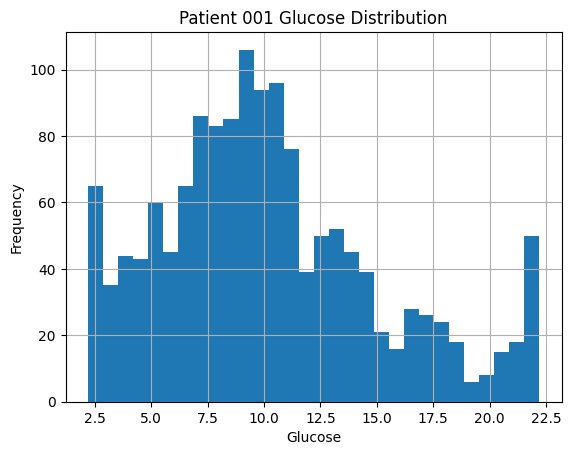

In [20]:
import matplotlib.pyplot as plt

glucose["glucose"].hist(bins=30)

plt.xlabel("Glucose")
plt.ylabel("Frequency")
plt.title("Patient 001 Glucose Distribution")

plt.show()

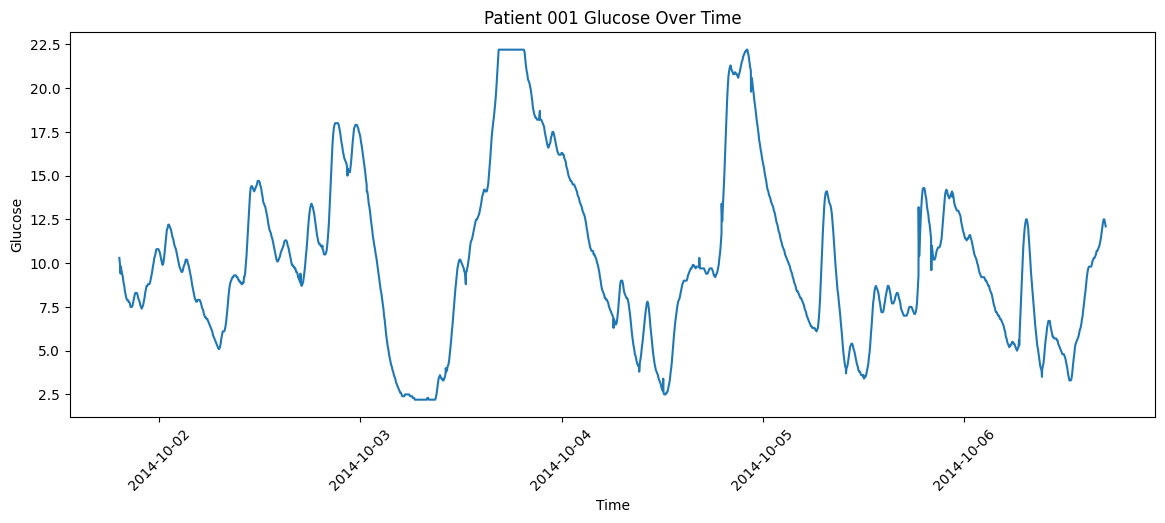

In [21]:
glucose["DateTime"] = pd.to_datetime(glucose["date"].astype(str) + " " + glucose["time"].astype(str))

plt.figure(figsize=(14, 5))

plt.plot(
    glucose["DateTime"],
    glucose["glucose"]
)

plt.xlabel("Time")
plt.ylabel("Glucose")
plt.title("Patient 001 Glucose Over Time")

plt.xticks(rotation=45)
plt.show()

In [22]:
print("Missing values each column")
for patient_id in sorted(patients.keys()):
    glucose = patients[patient_id]["glucose"]

    print(f"\nPatient {patient_id}")
    print("Rows:", len(glucose))
    print(glucose.isna().sum())

Missing values each column

Patient 001
Rows: 1438
date           0
time           0
glucose        0
type           0
comments    1438
DateTime       0
dtype: int64

Patient 002
Rows: 1071
date           0
time           0
glucose        0
type           0
comments    1071
dtype: int64

Patient 003
Rows: 185
date          0
time          0
glucose       0
type          0
comments    185
dtype: int64

Patient 004
Rows: 984
date          0
time          0
glucose       0
type          0
comments    984
dtype: int64

Patient 005
Rows: 928
date          0
time          0
glucose       0
type          0
comments    928
dtype: int64

Patient 006
Rows: 1298
date           0
time           0
glucose        0
type           0
comments    1298
dtype: int64

Patient 007
Rows: 1011
date           0
time           0
glucose        0
type           0
comments    1011
dtype: int64

Patient 008
Rows: 1175
date           0
time           0
glucose        0
type           0
comments    1175
dtype: int6

In [23]:
#size for each df of each patient
for patient_id in sorted(patients.keys()):
    print(
        patient_id,
        "Glucose:", patients[patient_id]["glucose"].shape,
        "Food:", patients[patient_id]["food"].shape,
        "Insulin:", patients[patient_id]["insulin"].shape
    )

001 Glucose: (1438, 6) Food: (26, 6) Insulin: (19, 5)
002 Glucose: (1071, 5) Food: (8, 6) Insulin: (13, 5)
003 Glucose: (185, 5) Food: (3, 6) Insulin: (9, 5)
004 Glucose: (984, 5) Food: (8, 6) Insulin: (14, 5)
005 Glucose: (928, 5) Food: (9, 6) Insulin: (7, 5)
006 Glucose: (1298, 5) Food: (7, 6) Insulin: (10, 5)
007 Glucose: (1011, 5) Food: (23, 6) Insulin: (16, 5)
008 Glucose: (1175, 5) Food: (20, 6) Insulin: (22, 5)
009 Glucose: (131, 5) Food: (11, 6) Insulin: (16, 5)


In [24]:
#average value for each patient
print("Average glucose")
for patient_id in sorted(patients.keys()):
    glucose = patients[patient_id]["glucose"]

    #print(f"Patient {patient_id}")
    print(f"Patient {patient_id}: {glucose["glucose"].mean()}")
    print()

Average glucose
Patient 001: 10.194089012517384

Patient 002: 10.160224089635856

Patient 003: 7.126486486486487

Patient 004: 11.197052845528457

Patient 005: 8.553125

Patient 006: 9.437057010785825

Patient 007: 8.287734915924828

Patient 008: 7.183489361702127

Patient 009: 4.337404580152671



### Insulin

In [25]:
insulin.head()

,date,time,fast_insulin,slow_insulin,comment
0,2014-10-01,10:06:00,7,NaN,NaN
1,2014-10-01,16:50:00,4,NaN,NaN
2,2014-10-01,19:28:00,6,NaN,NaN
3,2014-10-01,22:27:00,8,NaN,NaN
4,2014-10-01,23:48:00,0,31.0,NaN


In [26]:
#check data types / missing values
insulin.info()
insulin.isna().sum()
insulin.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          19 non-null     object 
 1   time          19 non-null     object 
 2   fast_insulin  19 non-null     int64  
 3   slow_insulin  3 non-null      float64
 4   comment       0 non-null      float64
dtypes: float64(2), int64(1), object(2)
memory usage: 892.0+ bytes


,date,time,fast_insulin,slow_insulin,comment
count,19,19,19.000000,3.0,0.0
unique,5,19,NaN,NaN,NaN
top,2014-10-01,10:06:00,NaN,NaN,NaN
freq,5,1,NaN,NaN,NaN
mean,NaN,NaN,6.421053,31.0,NaN
std,NaN,NaN,3.686549,0.0,NaN
min,NaN,NaN,0.000000,31.0,NaN
25%,NaN,NaN,3.500000,31.0,NaN
50%,NaN,NaN,7.000000,31.0,NaN
75%,NaN,NaN,8.500000,31.0,NaN


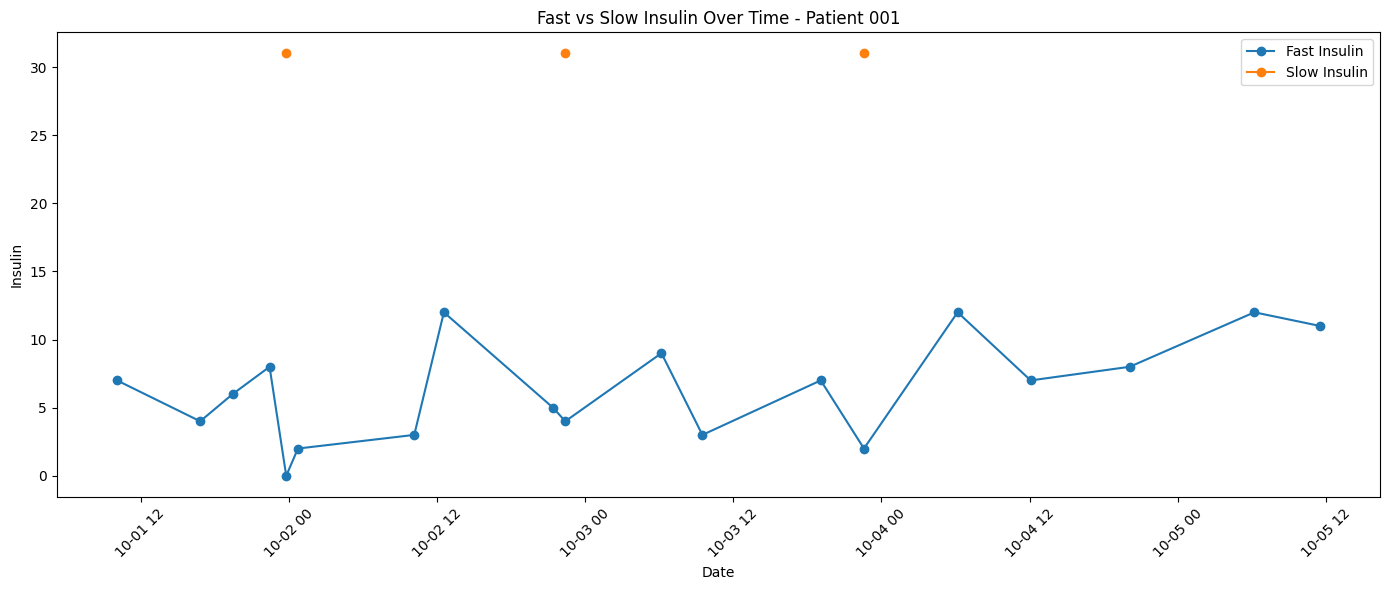

In [27]:
insulin = patients["001"]["insulin"].copy()

# Combine date and time
insulin["DateTime"] = pd.to_datetime(
    insulin["date"].astype(str) + " " + insulin["time"].astype(str)
)

# Sort chronologically
insulin = insulin.sort_values("DateTime")

# Plot
plt.figure(figsize=(14, 6))

plt.plot(
    insulin["DateTime"],
    insulin["fast_insulin"],
    marker="o",
    label="Fast Insulin"
)

plt.plot(
    insulin["DateTime"],
    insulin["slow_insulin"],
    marker="o",
    label="Slow Insulin"
)

plt.xlabel("Date")
plt.ylabel("Insulin")
plt.title("Fast vs Slow Insulin Over Time - Patient 001")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [28]:
# missing values across patients
print("Missing values each column")
for patient_id in sorted(patients.keys()):
    insulin = patients[patient_id]["insulin"]

    print(f"\nPatient {patient_id}")
    print("Rows:", len(insulin))
    print(insulin.isna().sum())

Missing values each column

Patient 001
Rows: 19
date             0
time             0
fast_insulin     0
slow_insulin    16
comment         19
dtype: int64

Patient 002
Rows: 13
date             0
time             0
fast_insulin     2
slow_insulin     6
comment         13
dtype: int64

Patient 003
Rows: 9
date            0
time            0
fast_insulin    6
slow_insulin    9
comment         9
dtype: int64

Patient 004
Rows: 14
date             0
time             0
fast_insulin     0
slow_insulin     0
comment         14
dtype: int64

Patient 005
Rows: 7
date            0
time            0
fast_insulin    0
slow_insulin    7
comment         7
dtype: int64

Patient 006
Rows: 10
date             0
time             0
fast_insulin     0
slow_insulin    10
comment         10
dtype: int64

Patient 007
Rows: 16
date             0
time             0
fast_insulin     0
slow_insulin    16
comment         16
dtype: int64

Patient 008
Rows: 22
date             0
time             0
fast_insulin   

In [29]:
#average value for each patient
print("Average Insulin Fast/Slow")
for patient_id in sorted(patients.keys()):
    insulin = patients[patient_id]["insulin"]

    print(f"Patient {patient_id}: Fast-{insulin["fast_insulin"].mean()}, Slow-{insulin["slow_insulin"].mean()}") 

Average Insulin Fast/Slow
Patient 001: Fast-6.421052631578948, Slow-31.0
Patient 002: Fast-5.2727272727272725, Slow-4.571428571428571
Patient 003: Fast-7.8, Slow-nan
Patient 004: Fast-4.0, Slow-6.857142857142857
Patient 005: Fast-1.7714285714285716, Slow-nan
Patient 006: Fast-5.55, Slow-nan
Patient 007: Fast-4.0625, Slow-nan
Patient 008: Fast-4.7272727272727275, Slow-nan
Patient 009: Fast-3.3846153846153846, Slow-18.0


### Food

In [30]:
food.head()

,picture,description,calories,balance,quality,datetime
0,001.jpg,Iceberg lettuce with olive oil and vinegar,357,Unbalance,Good quality,2014:10:01 19:27:49
1,002.jpg,"Tuna salade with boiled egg, asiago cheese an...",866,Unbalance,Good quality,2014:10:01 19:32:00
2,003.jpg,Asiago cheese,190,Unbalance,Good quality,2014:10:01 19:43:59
3,004.jpg,"Lemon yogurt, asiago cheese and bread with kiwi",1063,Balance,Good quality,2014:10:02 10:11:16
4,005.jpg,Tomatoes with cheese and bread,979,Unbalance,Good quality,2014:10:02 19:34:03


In [31]:
#check data types / missing values
food.info()
food.isna().sum()
food.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   picture      26 non-null     object
 1   description  26 non-null     object
 2   calories     26 non-null     int64 
 3   balance      26 non-null     object
 4   quality      26 non-null     object
 5   datetime     26 non-null     object
dtypes: int64(1), object(5)
memory usage: 1.3+ KB


,picture,description,calories,balance,quality,datetime
count,26,26,26.000000,26,26,26
unique,26,24,NaN,2,3,26
top,001.jpg,Solevita multivitamin,NaN,Unbalance,Good quality,2014:10:01 19:27:49
freq,1,2,NaN,23,10,1
mean,NaN,NaN,518.923077,NaN,NaN,NaN
std,NaN,NaN,501.124090,NaN,NaN,NaN
min,NaN,NaN,42.000000,NaN,NaN,NaN
25%,NaN,NaN,191.250000,NaN,NaN,NaN
50%,NaN,NaN,365.500000,NaN,NaN,NaN
75%,NaN,NaN,709.000000,NaN,NaN,NaN


In [32]:
# missing values across patients
for patient_id in sorted(patients.keys()):
    food = patients[patient_id]['food']

    print(f"\nPatient {patient_id}")
    print("Rows:", len(food))
    print(food.isna().sum())


Patient 001
Rows: 26
picture        0
description    0
calories       0
balance        0
quality        0
datetime       0
dtype: int64

Patient 002
Rows: 8
picture        0
description    0
calories       0
balance        0
quality        0
datetime       0
dtype: int64

Patient 003
Rows: 3
picture        0
description    0
calories       0
balance        0
quality        0
datetime       0
dtype: int64

Patient 004
Rows: 8
picture        0
description    0
calories       0
balance        0
quality        0
datetime       0
dtype: int64

Patient 005
Rows: 9
picture        9
description    0
calories       0
balance        0
quality        0
datetime       9
dtype: int64

Patient 006
Rows: 7
picture        0
description    0
calories       0
balance        0
quality        0
datetime       0
dtype: int64

Patient 007
Rows: 23
picture        0
description    0
calories       0
balance        0
quality        0
datetime       0
dtype: int64

Patient 008
Rows: 20
picture        0
descrip

In [33]:
print("Most occurred input / frequency")
for patient_id in sorted(patients.keys()):
    print(f"\n--------{patient_id}---------")

    for data_type in ["food"]:
        df = patients[patient_id][data_type]

        object_columns = df.select_dtypes(include="object").columns

        for column in object_columns:
            counts = df[column].value_counts()
            if not counts.empty:
                most_common = counts.index[0]
                frequency = counts.iloc[0]

                print(f"{column}: {most_common} ({frequency})")

Most occurred input / frequency

--------001---------
picture: 001.jpg (1)
description: Solevita multivitamin (2)
balance: Unbalance (23)
quality: Good quality (10)
datetime: 2014:10:01 19:27:49 (1)

--------002---------
picture: 001.jpg (1)
description: Margarita pizza and lettuce,tomatoes and cucumber salad (1)
balance: Unbalance (7)
quality: Good quality (6)
datetime: 2014:10:01 19:43:25 (1)

--------003---------
picture: 001.jpg (1)
description: Pizza parmesan ham (1)
balance: Unbalance (3)
quality: Medium quality (2)
datetime: 2014:10:01 12:15:05 (1)

--------004---------
picture: 001.jpg (1)
description: Lettuce with carrots and dressing (1)
balance: Unbalance (8)
quality: Low quality (4)
datetime: 2014:10:01 12:25:47 (1)

--------005---------
description: Bread without gluten and mermelade and coffee (3)
balance: Unbalance (8)
quality: Good quality (4)

--------006---------
picture: 001.jpg (1)
description: Corn flakes and grapefruit juice (1)
balance: Unbalance (7)
quality: Low

In [34]:
food = patients["001"]["food"]
food['quality'].unique()

array(['Good quality', 'Low quality', 'Medium quality'], dtype=object)

In [35]:
# Food - already combined
food["DateTime"] = pd.to_datetime(
    food["datetime"],
    format="%Y:%m:%d %H:%M:%S"
)

# Glucose - separate date and time
glucose["DateTime"] = pd.to_datetime(
    glucose["date"].astype(str) + " " + glucose["time"].astype(str)
)

# Insulin - separate date and time
insulin["DateTime"] = pd.to_datetime(
    insulin["date"].astype(str) + " " + insulin["time"].astype(str)
)

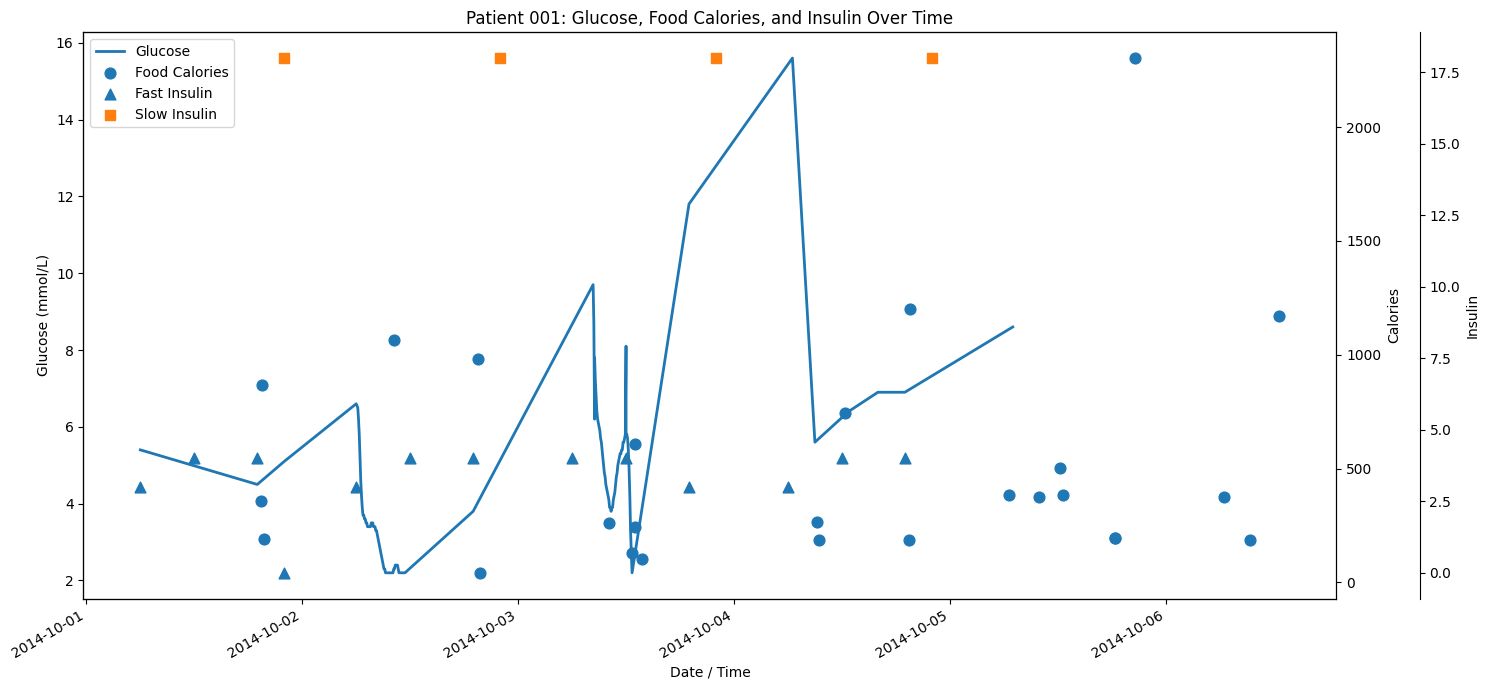

In [36]:
import matplotlib.pyplot as plt

# Sort everything by time
glucose = glucose.sort_values("DateTime")
food = food.sort_values("DateTime")
insulin = insulin.sort_values("DateTime")

fig, ax1 = plt.subplots(figsize=(15, 7))

# -------------------------
# Glucose
# -------------------------
ax1.plot(
    glucose["DateTime"],
    glucose["glucose"],
    linewidth=2,
    label="Glucose"
)

ax1.set_xlabel("Date / Time")
ax1.set_ylabel("Glucose (mmol/L)")


# -------------------------
# Calories
# -------------------------
ax2 = ax1.twinx()

ax2.scatter(
    food["DateTime"],
    food["calories"],
    marker="o",
    s=60,
    label="Food Calories"
)

ax2.set_ylabel("Calories")


# -------------------------
# Insulin
# -------------------------
ax3 = ax1.twinx()

# Move third axis slightly to the right
ax3.spines["right"].set_position(("outward", 60))

ax3.scatter(
    insulin["DateTime"],
    insulin["fast_insulin"],
    marker="^",
    s=60,
    label="Fast Insulin"
)

ax3.scatter(
    insulin["DateTime"],
    insulin["slow_insulin"],
    marker="s",
    s=60,
    label="Slow Insulin"
)

ax3.set_ylabel("Insulin")


# -------------------------
# Combine legends
# -------------------------
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
lines3, labels3 = ax3.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2 + lines3,
    labels1 + labels2 + labels3,
    loc="upper left"
)

plt.title("Patient 001: Glucose, Food Calories, and Insulin Over Time")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Accelerometer Subset

only patient 001 studied

In [37]:
# acclerometer, heart rate, breathing rate, and activity data
sum1 = pd.read_csv('/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_sensor_data/diabetes_subset_sensor_data/001/sensor_data/2014_10_01-10_09_39/2014_10_01-10_09_39_Summary.csv')

sum2 = pd.read_csv('/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_sensor_data/diabetes_subset_sensor_data/001/sensor_data/2014_10_02-10_56_44/2014_10_02-10_56_44_Summary.csv')
sum3 = pd.read_csv('/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_sensor_data/diabetes_subset_sensor_data/001/sensor_data/2014_10_03-06_36_24/2014_10_03-06_36_24_Summary.csv')
sum4 = pd.read_csv('/kaggle/input/datasets/sarabhian/d1namo-ecg-glucose-data/diabetes_subset_sensor_data/diabetes_subset_sensor_data/001/sensor_data/2014_10_04-06_34_57/2014_10_04-06_34_57_Summary.csv')

summary = pd.concat([sum1, sum2, sum3, sum4])

summary['Time'] = pd.to_datetime(summary['Time'], format='%m/%d/%Y %H:%M:%S.%f')

summary['Time'] = summary['Time'].apply(lambda x: x.replace(month=x.day, day=x.month))
summary.sort_values(by='Time', inplace=True)

summary


,Time,HR,BR,SkinTemp,Posture,Activity,PeakAccel,BatteryVolts,BatteryLevel,BRAmplitude,...,SagittalPeak,DeviceTemp,StatusInfo,LinkQuality,RSSI,TxPower,CoreTemp,AuxADC1,AuxADC2,AuxADC3
0,2014-10-01 10:09:39.417,65,8.1,-3276.8,19,0.41,0.84,4.161,93,5973.0,...,0.39,24.9,528,255,-128,-128,6553.5,420,433,499
1,2014-10-01 10:09:40.417,65,8.1,-3276.8,9,0.51,1.03,4.161,93,5361.0,...,0.36,24.9,528,255,-128,-128,6553.5,419,428,485
2,2014-10-01 10:09:41.417,65,7.3,-3276.8,11,0.30,0.74,4.161,93,4733.0,...,0.12,24.9,528,255,-128,-128,6553.5,415,420,484
3,2014-10-01 10:09:42.417,65,7.3,-3276.8,18,0.43,0.98,4.161,93,4094.0,...,0.49,24.9,528,255,-128,-128,6553.5,415,422,484
4,2014-10-01 10:09:43.417,65,6.6,-3276.8,19,0.49,1.10,4.161,93,3566.0,...,0.44,24.9,528,255,-128,-128,6553.5,399,406,480
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25979,2014-10-04 13:47:56.423,0,18.4,-3276.8,-7,0.07,0.10,3.888,48,67.0,...,0.22,32.4,531,255,-128,-128,35.3,409,419,461
25980,2014-10-04 13:47:57.423,0,17.7,-3276.8,-7,0.07,0.08,3.888,48,60.0,...,0.12,32.4,531,255,-128,-128,35.3,414,420,483
25981,2014-10-04 13:47:58.423,0,17.7,-3276.8,-7,0.05,0.08,3.888,48,53.0,...,0.12,32.4,531,255,-128,-128,35.3,419,424,486
25982,2014-10-04 13:47:59.423,0,16.9,-3276.8,-8,0.02,0.04,3.888,48,47.0,...,0.13,32.4,531,255,-128,-128,35.3,415,421,483


In [38]:
print(summary.columns)

Index(['Time', 'HR', 'BR', 'SkinTemp', 'Posture', 'Activity', 'PeakAccel',
       'BatteryVolts', 'BatteryLevel', 'BRAmplitude', 'BRNoise',
       'BRConfidence', 'ECGAmplitude', 'ECGNoise', 'HRConfidence', 'HRV',
       'SystemConfidence', 'GSR', 'ROGState', 'ROGTime', 'VerticalMin',
       'VerticalPeak', 'LateralMin', 'LateralPeak', 'SagittalMin',
       'SagittalPeak', 'DeviceTemp', 'StatusInfo', 'LinkQuality', 'RSSI',
       'TxPower', 'CoreTemp', 'AuxADC1', 'AuxADC2', 'AuxADC3'],
      dtype='object')


In [ ]:
# split into different categories

#physiological  / vital
phys_state = summary[['Time','HR', 'BR', 'HRV', 'CoreTemp', 'SkinTemp', 'GSR']]

#movement / activity
activity = summary[['Time','Activity', 'Posture', 'PeakAccel', 'VerticalMin', 'VerticalPeak',
                    'LateralMin', 'LateralPeak', 'SagittalMin', 'SagittalPeak'
                    ]]

#ECG / heart signal quality
ecg_quality = summary[['Time','ECGAmplitude', 'ECGNoise', 'HRConfidence']]

#breathing signal quality
breathing = summary[['Time','BRAmplitude', 'BRNoise', 'BRConfidence']]

#overall data quality and time
sum_data = summary[['Time', 'SystemConfidence']]

#device hardware
device = summary[['Time','BatteryVolts', 'BatteryLevel', 'DeviceTemp', 'StatusInfo']]

#wireless/communication
comm = summary[['Time','LinkQuality', 'RSSI', 'TxPower']]

#system/receiver
rog = summary[['Time','ROGState', 'ROGTime']]

#auxiliary sensor inputs
aux = summary[['Time','AuxADC1', 'AuxADC2', 'AuxADC3']]


### physiological / vital

In [44]:
#check duplicates
print("duplicates:", glucose.duplicated().sum())


#check data types / missing values
phys_state.info()
phys_state.isna().sum()
phys_state.describe(include="all")

#understand values
phys_state.describe()

duplicates: 0
<class 'pandas.core.frame.DataFrame'>
Index: 154486 entries, 0 to 25983
Data columns (total 7 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Time      154486 non-null  datetime64[ns]
 1   HR        154486 non-null  int64         
 2   BR        154486 non-null  float64       
 3   HRV       154486 non-null  int64         
 4   CoreTemp  154486 non-null  float64       
 5   SkinTemp  154486 non-null  float64       
 6   GSR       154486 non-null  int64         
dtypes: datetime64[ns](1), float64(3), int64(3)
memory usage: 9.4 MB


,Time,HR,BR,HRV,CoreTemp,SkinTemp,GSR
count,154486,154486.000000,154486.000000,154486.000000,154486.000000,1.544860e+05,154486.0
mean,2014-10-02 22:37:58.661618176,47.788783,18.520966,59169.391401,45.852622,-3.276800e+03,65535.0
min,2014-10-01 10:09:39.417000,0.000000,0.000000,26.000000,35.100000,-3.276800e+03,65535.0
25%,2014-10-01 20:53:20.666999808,0.000000,12.200000,65535.000000,35.500000,-3.276800e+03,65535.0
50%,2014-10-02 20:10:19.920000,60.000000,16.200000,65535.000000,36.300000,-3.276800e+03,65535.0
75%,2014-10-03 15:49:21.170999808,82.000000,20.600000,65535.000000,37.300000,-3.276800e+03,65535.0
max,2014-10-04 13:48:00.423000,240.000000,6553.500000,65535.000000,6553.500000,-3.276800e+03,65535.0
std,NaN,45.334390,106.695037,19397.268242,247.983537,8.202305e-09,0.0


In [48]:
phys_state['GSR'].unique()
#phys_state['HRV'].unique()
#phys_state['SkinTemp'].unique()

array([65535])

In [41]:
activity.describe()

,Time,Activity,Posture,PeakAccel,VerticalMin,VerticalPeak,LateralMin,LateralPeak,SagittalMin,SagittalPeak
count,154486,154486.000000,154486.000000,154486.000000,154486.000000,154486.000000,154486.000000,154486.000000,154486.000000,154486.000000
mean,2014-10-02 22:37:58.661618176,0.062966,-11.182657,0.136507,-1.017679,-0.855214,-0.227317,-0.087082,0.086625,0.247677
min,2014-10-01 10:09:39.417000,0.000000,-124.000000,0.010000,-10.510000,-1.000000,-8.420000,-0.900000,-7.810000,-0.920000
25%,2014-10-01 20:53:20.666999808,0.010000,-22.000000,0.040000,-1.060000,-0.960000,-0.360000,-0.240000,-0.080000,0.080000
50%,2014-10-02 20:10:19.920000,0.020000,-15.000000,0.060000,-1.020000,-0.920000,-0.250000,-0.090000,0.060000,0.220000
75%,2014-10-03 15:49:21.170999808,0.070000,-9.000000,0.140000,-0.960000,-0.810000,-0.060000,0.040000,0.320000,0.440000
max,2014-10-04 13:48:00.423000,1.480000,124.000000,7.550000,0.500000,4.280000,0.840000,2.970000,0.800000,3.460000
std,NaN,0.096721,22.217143,0.198126,0.205874,0.165120,0.238606,0.201999,0.324518,0.270435


In [42]:
ecg_quality.describe()

,Time,ECGAmplitude,ECGNoise,HRConfidence
count,154486,154486.000000,154486.000000,154486.000000
mean,2014-10-02 22:37:58.661618176,0.001207,0.000329,23.814126
min,2014-10-01 10:09:39.417000,0.000000,0.000000,0.000000
25%,2014-10-01 20:53:20.666999808,0.000800,0.000060,1.000000
50%,2014-10-02 20:10:19.920000,0.000800,0.000140,1.000000
75%,2014-10-03 15:49:21.170999808,0.001420,0.000320,37.000000
max,2014-10-04 13:48:00.423000,0.059480,0.021320,100.000000
std,NaN,0.001332,0.000624,36.096549
